# Support vector machines

[Logistic regression](../algorithms/linear-models/logistic_regression.ipynb) separates two classes with a line, placed where it makes the observed classes most probable, and every training point has a say in where it goes. A **support vector machine** (SVM) asks a different question: of all the lines that separate the classes, which one leaves the widest empty band, the **margin**, between them? Only the points at the edge of that band decide where the line goes; they are the **support vectors**. With *kernels*, the same idea draws curved boundaries.

## The widest margin

Two groups of points that a straight line can separate, and an SVM with a linear kernel:

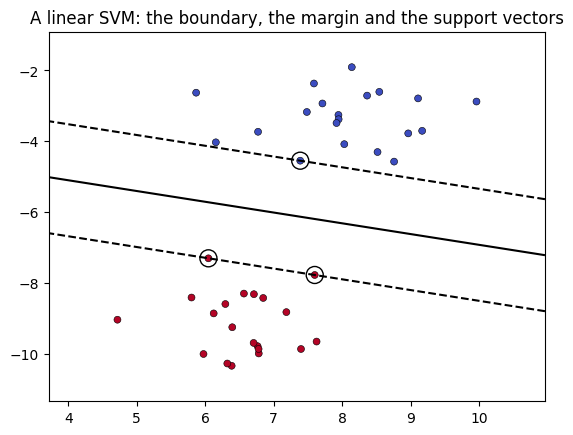

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_blobs
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.svm import SVC

X_blobs, y_blobs = make_blobs(n_samples=40, centers=2, cluster_std=0.8, random_state=6)
separable_svm = SVC(kernel="linear", C=1000).fit(X_blobs, y_blobs)


def plot_svm(model, X, y, title):
    DecisionBoundaryDisplay.from_estimator(model, X, response_method="decision_function", plot_method="contour",
                                           levels=[-1, 0, 1], linestyles=["--", "-", "--"], colors="k")
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=25, edgecolors="k", linewidths=0.4)
    plt.scatter(model.support_vectors_[:, 0], model.support_vectors_[:, 1], s=150, facecolors="none", edgecolors="k")
    plt.title(title)
    plt.show()


plot_svm(separable_svm, X_blobs, y_blobs, "A linear SVM: the boundary, the margin and the support vectors")

The solid line is the boundary; the dashed lines are the edges of the margin; the circled points are the support vectors. The boundary is the line in the middle of the widest band that has no training point inside it. Its width is $2 / \lVert w \rVert$, where $w$ are the weights of the line, so finding the widest margin is minimising the size of the weights while keeping every point on its side and outside the margin: a convex optimisation problem, with a single best solution and no local minima, which scikit-learn's `SVC` finds iteratively. The figure follows scikit-learn's example [SVM: Maximum margin separating hyperplane](https://scikit-learn.org/stable/auto_examples/svm/plot_separating_hyperplane.html) (BSD-3-Clause licence, Copyright (c) 2007-2024 The scikit-learn developers).

In [ ]:
separable_svm.n_support_, 2 / np.linalg.norm(separable_svm.coef_)

(array([1, 2], dtype=int32), np.float64(3.0204442988074214))

Only the support vectors matter. Removing a point far from the boundary and fitting again gives exactly the same line:

In [ ]:
farthest = np.argmax(np.abs(separable_svm.decision_function(X_blobs)))
refitted = SVC(kernel="linear", C=1000).fit(np.delete(X_blobs, farthest, axis=0), np.delete(y_blobs, farthest))
np.allclose(separable_svm.coef_, refitted.coef_), np.allclose(separable_svm.intercept_, refitted.intercept_)

(True, True)

A logistic regression fitted again without that point would move a little: every point pulls on it. An SVM is moved only by the points near the border, which makes it robust to what happens far from it, and sensitive to what happens near it.

## Soft margins and C

Real classes overlap, and no line separates them perfectly. A **soft margin** allows points inside the margin, or even on the wrong side, at a cost. The setting `C` decides how much each violation costs: a large `C` forbids them as much as possible, and the margin narrows to fit the training points; a small `C` tolerates them, and the margin widens. It is the complexity setting of an SVM, like the depth of a tree ([Controlling complexity](../ml-fundamentals/regularization.ipynb)):

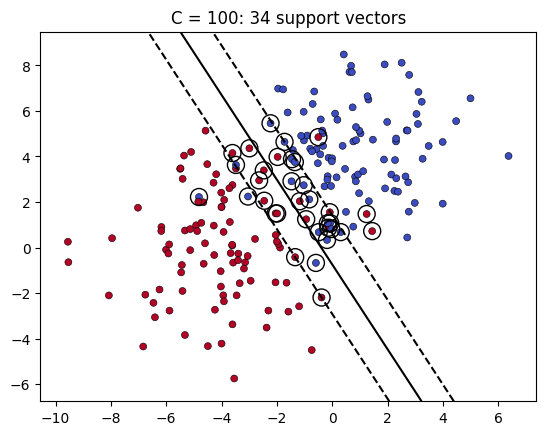

In [ ]:
X_overlap, y_overlap = make_blobs(n_samples=200, centers=2, cluster_std=2.0, random_state=3)
strict = SVC(kernel="linear", C=100).fit(X_overlap, y_overlap)
plot_svm(strict, X_overlap, y_overlap, f"C = 100: {strict.n_support_.sum()} support vectors")

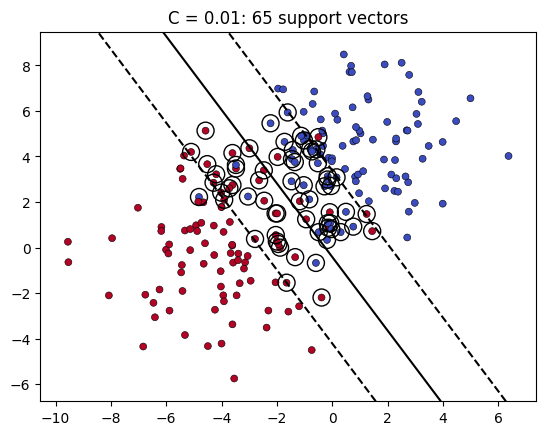

In [ ]:
tolerant = SVC(kernel="linear", C=0.01).fit(X_overlap, y_overlap)
plot_svm(tolerant, X_overlap, y_overlap, f"C = 0.01: {tolerant.n_support_.sum()} support vectors")

With C = 100, violations are expensive: the margin is narrow, and 34 points, those inside it or on the wrong side, are support vectors. With C = 0.01, violations are cheap: the margin widens to take in most of the overlap, and 65 points support the boundary, each with a smaller say. The boundary itself moves only a little here, because the overlap is symmetric; with a curved kernel (below), a large C lets the boundary bend around individual points, and a small C keeps it smooth.

## Kernels: curved boundaries

Two interleaved half-moons can't be separated by a line. One way out would be to add features, products and powers of the coordinates, in which a separating plane exists, as polynomial features did for [regularisation](../ml-fundamentals/regularization.ipynb). The margin problem has a property that makes this cheap: it only needs the *similarity* between pairs of points, never the new features themselves. A **kernel** is a function that computes that similarity directly, as if the points had been mapped to the larger space, without ever building it. This is the **kernel trick**.

The usual kernel, scikit-learn's default, is the **radial basis function** (RBF): $k(x, x') = e^{-\gamma \lVert x - x' \rVert^2}$, a similarity of 1 for identical points that fades with distance. A linear SVM and an RBF SVM on the moons:

In [ ]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

X_moons, y_moons = make_moons(n_samples=300, noise=0.2, random_state=0)
X_train, X_test, y_train, y_test = train_test_split(X_moons, y_moons, test_size=0.3, random_state=0)
linear_svm = SVC(kernel="linear").fit(X_train, y_train)
rbf_svm = SVC(kernel="rbf").fit(X_train, y_train)
{"linear kernel, test accuracy": linear_svm.score(X_test, y_test), "RBF kernel, test accuracy": rbf_svm.score(X_test, y_test)}

{'linear kernel, test accuracy': 0.8666666666666667,
 'RBF kernel, test accuracy': 1.0}

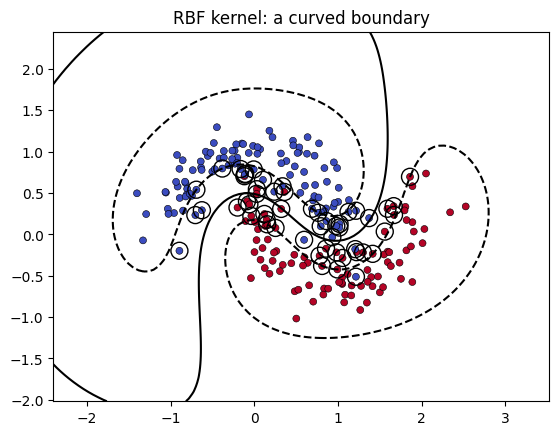

In [ ]:
plot_svm(rbf_svm, X_train, y_train, "RBF kernel: a curved boundary")

`gamma` decides how far a point's influence reaches. With a small `gamma`, each point influences a wide area and the boundary is smooth; with a large one, each point only influences its immediate surroundings, and the boundary can wrap around individual points:

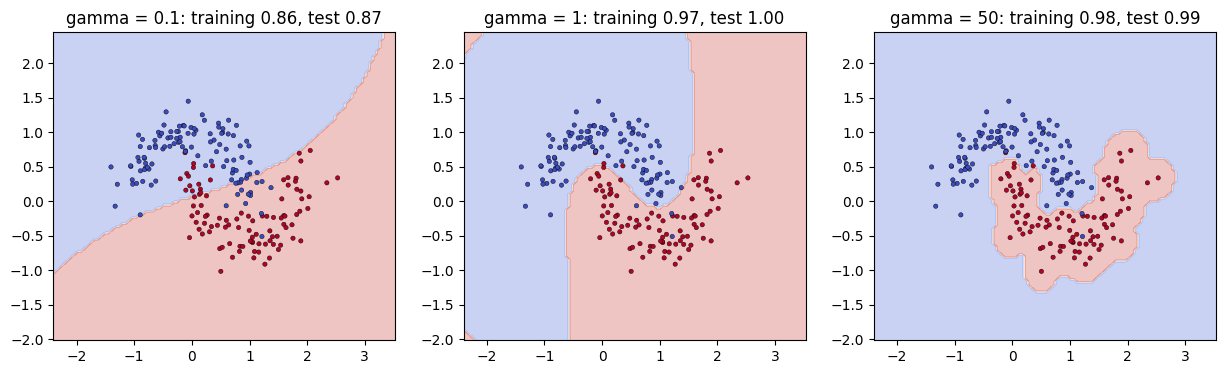

In [ ]:
figure, axes = plt.subplots(1, 3, figsize=(15, 4))
for axis, gamma in zip(axes, (0.1, 1, 50)):
    model = SVC(gamma=gamma).fit(X_train, y_train)
    DecisionBoundaryDisplay.from_estimator(model, X_moons, response_method="predict", alpha=0.3, cmap="coolwarm", ax=axis)
    axis.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap="coolwarm", s=10, edgecolors="k", linewidths=0.3)
    axis.set_title(f"gamma = {gamma}: training {model.score(X_train, y_train):.2f}, test {model.score(X_test, y_test):.2f}")
plt.show()

With gamma = 0.1 the boundary is a gentle curve, too smooth for the moons: 0.87 on the test points, no better than a straight line. With gamma = 1 it follows the moons, and every test point is classified correctly. With gamma = 50 each point's influence reaches only its immediate surroundings: the red region hugs the red training points, and everything else is blue. Its test score is still 0.99, because the test points lie in the same dense areas as the training points; a new point a little beyond the end of the red moon would be called blue. A high test score can hide a model that would fail on the first point unlike the data it has seen.

## Scaling

An SVM's margin and its RBF kernel are both built on distances, so, as for [k-nearest neighbours](../algorithms/neighbours/knn.ipynb#why-scaling-matters), a feature measured in large numbers dominates the others. On the breast cancer data of [Evaluating a classifier](../evaluation/classification_metrics.ipynb), whose 30 measurements range from fractions to thousands, by cross-validation:

In [ ]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

cancer = load_breast_cancer()
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
{
    "without scaling": cross_val_score(SVC(), cancer.data, cancer.target, cv=folds).mean(),
    "with scaling": cross_val_score(make_pipeline(StandardScaler(), SVC()), cancer.data, cancer.target, cv=folds).mean(),
}

{'without scaling': np.float64(0.92100605496041),
 'with scaling': np.float64(0.9771464058376029)}

From 0.92 to 0.98 of accuracy, only by putting the 30 measurements on a common scale. Without it, a few measurements of areas, in the hundreds or thousands, decide every distance, and the rest barely count.

## Regression

The same idea predicts numbers with `SVR`: instead of a band with no points inside, it fits a band of width $2\varepsilon$ (the setting `epsilon`) around the prediction, and ignores errors that fall inside it. Only the points outside the band, or on its edge, become support vectors and shape the model. Kernels and `C` work as in classification.

## Where SVMs stand

In the 2000s, SVMs with kernels were among the best classifiers available, for text, images and biological data. Three things limit them today:

- **Training time grows fast with the number of rows**, between the square and the cube of it for kernel SVMs, which rules them out beyond some tens of thousands of rows. ([A classifier in depth (MNIST)](../evaluation/deep-dives/mnist_classifier_in_depth.ipynb) measures it.) `LinearSVC` and `SGDClassifier` train linear SVMs on large data, without kernels.
- **No probabilities.** An SVM gives a distance to the boundary, not a probability; `SVC(probability=True)` estimates one with an extra internal cross-validation, at a cost.
- **Stronger alternatives:** on tables, [gradient boosting](../algorithms/tree-based/gradient_boosting.ipynb) is usually more accurate with less tuning; on images, sound and text, neural networks learn their own features.

They remain a good choice for small and medium datasets with many features, such as text represented by word counts, measurements of genes, or signals, where a linear SVM or an RBF SVM with tuned `C` and `gamma` is fast and hard to beat.

## Settings

| Setting | Meaning | Effect |
| --- | --- | --- |
| `kernel` | `"linear"`, `"rbf"` (default), `"poly"` | the shape of the boundary |
| `C` | cost of each point inside the margin or on the wrong side | larger: narrower margin, more flexible model |
| `gamma` | reach of each point's influence, for the RBF kernel | larger: more local, more flexible model |
| `class_weight` | extra cost for errors on a class | as in [When one class is rare](../evaluation/imbalanced_classes.ipynb#weighting-the-classes) |

`C` and `gamma` interact, and are searched together, on a logarithmic grid, by cross-validation ([Cross-validation and hyperparameter search](../ml-fundamentals/cross_validation_and_search.ipynb)), always with the scaler inside the pipeline.